In [1]:
!pip install numpy matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt


In [3]:
##### 1. Create the environment
rows = 4
cols = 4

start = 0
goal = 15

traps = [5, 7, 11, 12]


In [4]:
# 2. Define actions
# 0 = Up, 1 = Down, 2 = Left, 3 = Right

actions = [0, 1, 2, 3]

In [5]:
# 3. Create Q-table
Q = np.zeros((16, 4))


In [6]:
# 4. Set hyperparameters
alpha = 0.1
gamma = 0.9
epsilon = 1.0
episodes = 3000

rewards_list = []

In [7]:
# 5. Function to perform an action
def move(state, action):

    row = state // cols
    col = state % cols

    if action == 0:
        row -= 1
    elif action == 1:
        row += 1
    elif action == 2:
        col -= 1
    elif action == 3:
        col += 1

    # Prevent movement outside the grid
    row = max(0, min(rows - 1, row))
    col = max(0, min(cols - 1, col))

    return row * cols + col

In [8]:
# 6. Q-Learning training
for episode in range(episodes):

    state = start
    total_reward = 0

    for step in range(100):

        # Epsilon-greedy action selection
        if np.random.random() < epsilon:
            action = np.random.choice(actions)
        else:
            action = np.argmax(Q[state])

        # Perform action
        next_state = move(state, action)

        # Calculate reward
        if next_state == goal:
            reward = 10
        elif next_state in traps:
            reward = -10
        else:
            reward = -1

        # Q-Learning formula
        Q[state, action] = Q[state, action] + alpha * (
            reward + gamma * np.max(Q[next_state]) 
            - Q[state, action]
        )

        total_reward += reward

        state = next_state

        # Stop if goal or trap is reached
        if state == goal or state in traps:
            break

    rewards_list.append(total_reward)

    # Reduce exploration gradually
    epsilon = max(0.01, epsilon * 0.995)

In [9]:
# 7. Display trained Q-table
print("Trained Q-Table:")
print(np.round(Q, 2))

Trained Q-Table:
[[ 0.54  1.81  0.49 -1.02]
 [-2.39 -9.69 -1.94  1.2 ]
 [-1.79  3.75 -2.37 -1.81]
 [-1.57 -6.86 -1.3  -1.56]
 [ 0.41  3.12  0.51 -9.99]
 [ 0.    0.    0.    0.  ]
 [-1.02  6.1  -6.86 -7.71]
 [ 0.    0.    0.    0.  ]
 [ 1.47 -9.88  2.77  4.58]
 [-9.91  4.8   2.85  6.2 ]
 [ 3.05  8.    4.17 -9.72]
 [ 0.    0.    0.    0.  ]
 [ 0.    0.    0.    0.  ]
 [ 0.53  0.46 -6.13  7.86]
 [ 5.22  6.57  4.49 10.  ]
 [ 0.    0.    0.    0.  ]]


In [10]:
# 8. Test the trained agent
state = start
path = [state]

for step in range(20):

    action = np.argmax(Q[state])

    state = move(state, action)
    path.append(state)

    if state == goal or state in traps:
        break

print("\nLearned Path:", path)

if state == goal:
    print("Agent successfully reached the goal!")
else:
    print("Agent did not reach the goal.")


Learned Path: [0, 4, 8, 9, 10, 14, 15]
Agent successfully reached the goal!


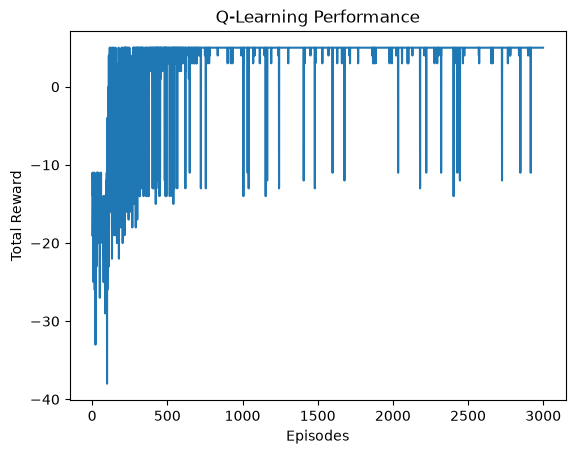

In [11]:

# 9. Plot learning performance
plt.plot(rewards_list)
plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("Q-Learning Performance")
plt.show()


In [ ]:
# 10. Play with the trained agent

def display_grid(state):

    for i in range(rows):
        for j in range(cols):

            pos = i * cols + j

            if pos == state:
                print(" A ", end="  ")
            elif pos == start:
                print(" S ", end="  ")
            elif pos == goal:
                print(" G ", end="  ")
            else:
                print(" . ", end="  ")

        print()


state = start

while state != goal and state not in traps:

    print("\nCurrent Grid:")
    display_grid(state)

    print("\nChoose an action:")
    print("1. Up")
    print("2. Down")
    print("3. Left")
    print("4. Right")
    print("5. Let AI choose")

    choice = int(input("Enter your choice: "))

    if choice < 1 or choice > 5:
        print("Invalid choice!")
        continue

    if choice == 5:
        action = np.argmax(Q[state])
        print("AI selected:", ["Up", "Down", "Left", "Right"][action])
    else:
        action = choice - 1

    next_state = move(state, action)

    if next_state == state:
        print("Cannot move outside the grid!")
        continue

    state = next_state

if state == goal:
    print("\nCongratulations! You reached the GOAL!")
elif state in traps:
    print("\nOops! You fell into a hidden trap!")

print("\nFinal Grid:")
display_grid(state)


Current Grid:
 A    .    .    .   
 .    .    .    .   
 .    .    .    .   
 .    .    .    G   

Choose an action:
1. Up
2. Down
3. Left
4. Right
5. Let AI choose
